# 03 - Preprocesamiento

Esta notebook toma los archivos crudos y deja en `data/processed/` los datos **limpios y listos para modelar**.

Qué hace:
1. Corrige un **error de carga del Excel** que deformó 18 columnas numéricas (el hallazgo más importante del TP).
2. Limpia: renombra columnas, descarta `oral`, codifica `gender` y `tartar` y trata un valor codificado en `eyesight`.
3. Detecta **registros duplicados** (la misma persona con distinto `ID`) y separa **train / validación** sin que una misma persona quede en los dos, **una sola vez**, antes de cualquier decisión basada en métricas.
4. Decide con **validación cruzada sobre train** (sin mirar validación) si sirven las variables nuevas y el `log1p`.
5. Aplica **la misma función** al archivo de entrega y guarda todo.

Lo que **no** hace: no escala, no balancea clases y no entrena el modelo final. Lo que necesita aprender de los datos (escalador, pesos de clase) va **dentro del pipeline** en la notebook 04, ajustado solo con train.

#### Dependencias

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import utils  # notebooks/utils.py: la limpieza que comparten la 03 y la 06

#### Parametros

In [2]:
RAW_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")
FILE_TRAIN = RAW_DIR / "smoking_prediction.xlsx"
FILE_ENTREGA = RAW_DIR / "smoking_prediction_entrega.xlsx"

TARGET = utils.TARGET
ID_COL = utils.ID_COL
RANDOM_STATE = 42
N_PARTES = 5  # validacion = 1 de 5 partes (~20%): alcanza para medir F1 con poco ruido

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

#### Funciones

In [3]:
def evaluar_cv(modelo, X, y, cv, grupos):
    # F1 de la clase 1 en train y en CV: la diferencia es el sobreajuste.
    # `grupos` mantiene juntos los registros duplicados (nunca uno en cada lado)
    r = cross_validate(modelo, X, y, cv=cv, scoring="f1", return_train_score=True, groups=grupos)
    return {"F1 train": r["train_score"].mean(), "F1 CV": r["test_score"].mean(),
            "desvio CV": r["test_score"].std()}


def agregar_features(df):
    # Combinaciones con sentido clinico propuestas en el EDA (02, seccion 6)
    df = df.copy()
    df["imc"] = df["weight_kg"] / (df["height_cm"] / 100) ** 2
    df["cintura_altura"] = df["waist_cm"] / df["height_cm"]
    df["tension_diferencial"] = df["systolic"] - df["relaxation"]
    df["col_hdl"] = df["cholesterol"] / df["hdl"]
    df["ldl_hdl"] = df["ldl"] / df["hdl"]
    df["tg_hdl"] = df["triglyceride"] / df["hdl"]
    df["ast_alt"] = df["ast"] / df["alt"]
    return df

## 1. Lectura

In [4]:
df_raw = pd.read_excel(FILE_TRAIN)
df_entrega_raw = pd.read_excel(FILE_ENTREGA)
print("Train:  ", df_raw.shape)
print("Entrega:", df_entrega_raw.shape)

Train:   (50000, 27)
Entrega: (5692, 26)


## 2. El error del Excel: números leídos como horas

En la notebook 01 se vio que muchas columnas parecían "divididas por 24" (por ejemplo `systolic` ≈ 5 en vez de ≈ 120). Mirando más de cerca, **no es una escala**: es que Excel interpretó los números como **horas** con el formato `h.mm` y los guardó como fracción de día.

| Valor original | Excel lo leyó como | Fracción de día guardada |
|---|---|---|
| `120` (systolic) | 120:00 hs | 120 / 24 = **5.0** |
| `1.0` (eyesight) | 1:00 hs | 1 / 24 = **0.0417** |
| `1.2` (eyesight) | **1:02** hs | (1 + 2/60) / 24 = **0.0431** |
| `0.8` (eyesight) | **0:08** hs | (8/60) / 24 = **0.0056** |

En los enteros el efecto es un simple ÷24. **En los decimales deforma los valores**: el decimal `.2` se convirtió en 2 minutos (2/60 = 0,033 en vez de 0,2). Por eso `eyesight` se veía bimodal en el EDA: `0.8` (0,0056) quedaba muy lejos de `1.0` (0,0417), cuando en realidad son vecinos.

**Cómo se verifica:** si la hipótesis es cierta, todo valor × 24 × 60 tiene que dar un número entero de minutos, y la parte de "minutos" nunca puede pasar de 9 (un decimal de una cifra va de 0 a 9).

In [5]:
cols_float = df_raw.select_dtypes("float").columns
chequeo = []
for nombre, d in [("train", df_raw), ("entrega", df_entrega_raw)]:
    for c in cols_float:
        minutos = d[c] * 24 * 60
        chequeo.append({
            "archivo": nombre, "columna": c,
            "error max vs entero": (minutos - minutos.round()).abs().max(),
            "max 'minutos'": int((minutos.round() % 60).max()),
        })
chequeo = pd.DataFrame(chequeo)
print("Columnas revisadas:", chequeo["columna"].nunique(), "x 2 archivos")
print("Error maximo contra un entero de minutos:", chequeo["error max vs entero"].max())
print("Maximo de 'minutos' encontrado:", chequeo["max 'minutos'"].max())

Columnas revisadas: 18 x 2 archivos
Error maximo contra un entero de minutos: 9.094947017729282e-13
Maximo de 'minutos' encontrado: 9


Se cumple en **todas** las columnas y en **los dos archivos**: el error es del orden de 10⁻¹², que es redondeo de punto flotante, y los "minutos" nunca superan 9. La corrección es exacta y no pierde información:

$$\text{valor original} = \text{horas} + \frac{\text{minutos}}{10}, \quad \text{con minutos} = x \cdot 24 \cdot 60$$

Está implementada en `utils.deshacer_hora_excel`, que además **corta con error** si algún valor no cumple el patrón. Así, si el archivo de entrega viniera distinto, la notebook 06 falla en vez de predecir con datos mal corregidos.

In [6]:
ejemplo = pd.DataFrame({
    "excel": df_raw["eyesight(left)"].head(6),
    "corregido": utils.deshacer_hora_excel(df_raw["eyesight(left)"].head(6)),
})
ejemplo

,excel,corregido
0,0.043056,1.2
1,0.005556,0.8
2,0.005556,0.8
3,0.045139,1.5
4,0.041667,1.0
5,0.043056,1.2


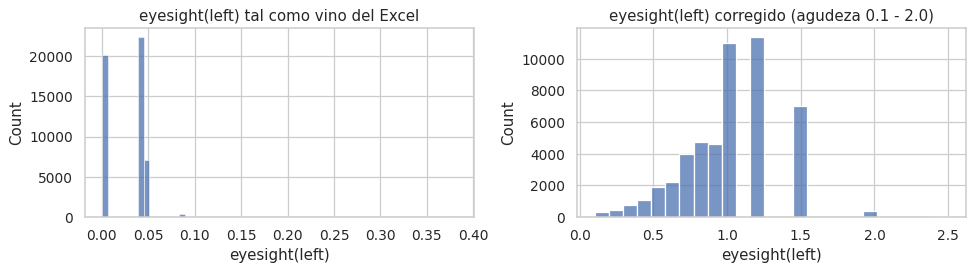

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
sns.histplot(df_raw["eyesight(left)"], bins=60, ax=axes[0])
axes[0].set_title("eyesight(left) tal como vino del Excel")
sns.histplot(utils.deshacer_hora_excel(df_raw["eyesight(left)"]).clip(upper=2.5), bins=25, ax=axes[1])
axes[1].set_title("eyesight(left) corregido (agudeza 0.1 - 2.0)")
plt.tight_layout(); plt.show()

La "bimodalidad" del EDA era un **artefacto del error**. Corregida, la agudeza visual queda en su escala real (0,1 a 2,0), con la moda en 1,0.

¿Importa para el modelo? La corrección **mantiene el orden** de los valores, así que a un árbol casi no le cambia nada (corta en umbrales, y el orden es el mismo). Pero sí importa para:
- **modelos lineales y KNN**, que usan las distancias entre valores;
- **las variables nuevas** (IMC, cocientes), que se calculan con los valores;
- **interpretar** resultados en unidades clínicas reales (hemoglobina 14,8 g/dL en vez de 0,59).

## 3. Limpieza completa

`utils.preparar(df)` hace todo en orden y **es la misma función que va a usar la notebook 06** con el archivo de entrega:

| Paso | Qué hace | Por qué |
|---|---|---|
| Renombrar | `height(cm)` → `height_cm`, etc. | Nombres sin espacios ni paréntesis, más cómodos en el pipeline |
| Descartar `oral` | Se elimina | Constante (`Y` en el 100% de los dos archivos) |
| Chequear nulos | Si hay, **corta con error** | Hoy no hay ninguno (ver 01). Imputar en silencio taparía un problema |
| Deshacer hora de Excel | 18 columnas vuelven a sus unidades | Sección 2 |
| `eyesight` = 9.9 → 0.0 | 9.9 es un código de ceguera, no una medición | Con 9.9 la persona ciega quedaría como la de "mejor vista" |
| `gender` M→1 / F→0, `tartar` Y→1 / N→0 | Codificación binaria | Son variables de 2 valores: alcanza con una columna 0/1. Si aparece otro valor, corta con error |

El `ID` **se conserva en los archivos** para poder rastrear filas y armar la entrega, pero **no entra al modelo**.

Todos los pasos son **fila por fila**: ninguno usa medias, medianas ni nada calculado sobre el conjunto. Por eso aplicarlos antes del split no genera fuga de información.

In [8]:
df = utils.preparar(df_raw)
df.head()

,id,gender,age,height_cm,weight_kg,waist_cm,eyesight_left,eyesight_right,hearing_left,hearing_right,systolic,relaxation,fasting_blood_sugar,cholesterol,triglyceride,hdl,ldl,hemoglobin,urine_protein,serum_creatinine,ast,alt,gtp,dental_caries,tartar,smoking
0,0,0,40,155,60,81.3,1.2,1.0,1,1,114.0,73.0,94.0,215.0,82.0,73.0,126.0,12.9,1,0.7,18.0,19.0,27.0,0,1,0
1,1,0,40,160,60,81.0,0.8,0.6,1,1,119.0,70.0,130.0,192.0,115.0,42.0,127.0,12.7,1,0.6,22.0,19.0,18.0,0,1,0
2,2,1,55,170,60,80.0,0.8,0.8,1,1,138.0,86.0,89.0,242.0,182.0,55.0,151.0,15.8,1,1.0,21.0,16.0,22.0,0,0,1
3,3,1,40,165,70,88.0,1.5,1.5,1,1,100.0,60.0,96.0,322.0,254.0,45.0,226.0,14.7,1,1.0,19.0,26.0,18.0,0,1,0
4,4,0,40,155,60,86.0,1.0,1.0,1,1,120.0,74.0,80.0,184.0,74.0,62.0,107.0,12.5,1,0.6,16.0,14.0,22.0,0,0,0


In [9]:
df.describe().T[["min", "50%", "max"]].round(2)

,min,50%,max
id,0.0,24999.5,55690.0
gender,0.0,1.0,1.0
age,20.0,40.0,85.0
height_cm,130.0,165.0,190.0
weight_kg,30.0,65.0,135.0
waist_cm,51.0,82.0,129.0
eyesight_left,0.0,1.0,2.0
eyesight_right,0.0,1.0,2.0
hearing_left,1.0,1.0,2.0
hearing_right,1.0,1.0,2.0


Ahora los valores están en unidades clínicas plausibles: cintura mediana 82 cm, presión 120/76, glucosa 96 mg/dL, colesterol 195 mg/dL, hemoglobina 14,8 g/dL, creatinina 0,9 mg/dL. `hearing` vale 1 o 2 y `Urine protein` va de 1 a 6, que son escalas ordinales.

Los extremos (ALT hasta 2914, GTP hasta 999) se **mantienen**, igual que se decidió en el EDA: son casos clínicos posibles y el archivo de entrega también los puede tener.

In [10]:
print("eyesight == 0 (ceguera recodificada):",
      int((df["eyesight_left"] == 0).sum()), "izq /", int((df["eyesight_right"] == 0).sum()), "der")
print("Codificacion gender:", df["gender"].value_counts().to_dict(), "(1 = M)")
print("Codificacion tartar:", df["tartar"].value_counts().to_dict(), "(1 = Y)")

eyesight == 0 (ceguera recodificada): 81 izq / 85 der
Codificacion gender: {1: 31784, 0: 18216} (1 = M)
Codificacion tartar: {1: 27789, 0: 22211} (1 = Y)



## 4. Registros duplicados

Hay filas idénticas en las 24 variables del modelo aunque tengan distinto `ID`. Se agrupan con `utils.grupos_duplicados` y se analizan.


In [11]:

features = [c for c in df.columns if c not in (ID_COL, TARGET)]
grupos = utils.grupos_duplicados(df, features)

tamanio = pd.Series(grupos).value_counts()
repetidos = tamanio[tamanio > 1]
print("Grupos con mas de una fila:", len(repetidos), "| filas involucradas:", int(repetidos.sum()),
      "| tamanio de los grupos:", sorted(repetidos.unique()))

consistencia = df.groupby(grupos)[TARGET].agg(["size", "nunique"])
print("Grupos repetidos con el mismo 'smoking' en todas sus filas:",
      f"{(consistencia.loc[consistencia['size'] > 1, 'nunique'] == 1).mean():.0%}")


Grupos con mas de una fila: 5448 | filas involucradas: 10896 | tamanio de los grupos: [np.int64(2)]
Grupos repetidos con el mismo 'smoking' en todas sus filas: 100%


In [12]:

# El archivo de entrega: cuantas filas son copia de una fila etiquetada
entrega_prep = utils.preparar(df_entrega_raw)
combinado = pd.concat([df[features], entrega_prep[features]], ignore_index=True)
g = utils.grupos_duplicados(combinado, features)
g_etiquetados, g_entrega = set(g[:len(df)]), g[len(df):]
print(f"Filas de la entrega con una copia entre los datos etiquetados: {np.isin(g_entrega, list(g_etiquetados)).mean():.1%}")


Filas de la entrega con una copia entre los datos etiquetados: 100.0%



- Son **5.448 pares** con las 24 mediciones idénticas (incluidos valores exactos de laboratorio) y **siempre el mismo `smoking`**: es la **misma persona registrada dos veces**, no una coincidencia.
- **Todas** las filas del archivo de entrega son copia de una persona etiquetada.

**Consecuencia:** si una copia queda en train y la otra en validación, el modelo "ya vio" a esa persona y la métrica se infla. Un modelo que memoriza saca ventaja, aunque generalice peor. Por eso, desde acá, **todo split y toda validación cruzada se hacen por grupo**: las dos copias de una persona van siempre del mismo lado.


## 5. Split train / validación

Se separa **ahora**, antes de tomar cualquier decisión basada en métricas:
- **train (~80%)**: se usa para todo (experimentos de esta notebook, búsqueda de hiperparámetros en la 04).
- **validación (~20%)**: no se toca hasta la notebook 05. Es la estimación honesta del F1 en personas nuevas.

Se usa `StratifiedGroupKFold` y se toma una de sus 5 partes como validación:
- **estratificado:** misma proporción de fumadores (~37%) en los dos conjuntos;
- **por grupo:** ninguna persona duplicada queda repartida entre train y validación;
- `random_state` fijo hace que el split sea reproducible.

In [13]:
separador = StratifiedGroupKFold(n_splits=N_PARTES, shuffle=True, random_state=RANDOM_STATE)
idx_train, idx_valid = next(separador.split(df, df[TARGET], groups=grupos))
train, valid = df.iloc[idx_train], df.iloc[idx_valid]

print(f"Train: {len(train):>6} filas | % fumadores: {train[TARGET].mean():.4f}")
print(f"Valid: {len(valid):>6} filas | % fumadores: {valid[TARGET].mean():.4f}")
print("Personas repartidas entre train y validacion:", len(set(grupos[idx_train]) & set(grupos[idx_valid])))

Train:  39999 filas | % fumadores: 0.3669
Valid:  10001 filas | % fumadores: 0.3652
Personas repartidas entre train y validacion: 0


## 6. Experimentos para decidir (solo con train)

Las decisiones se toman con **validación cruzada estratificada y por grupo de 5 folds sobre train** (`StratifiedGroupKFold`: los duplicados nunca quedan separados), usando el F1 de la clase 1 (la métrica del TP). No se usa correlación contra el target binario. En cada experimento se reporta **F1 en train y F1 en CV**: si train queda muy por encima, hay sobreajuste.

Modelo de prueba: `HistGradientBoostingClassifier` con parámetros por defecto. No es el modelo final: sirve como referencia para comparar versiones de los datos.

**Criterio:** todas las variantes se evalúan sobre los mismos 5 folds. Un cambio se adopta si mejora el F1 en todos los folds y la mejora es relevante (no unas pocas milésimas). Si no, se prefiere lo más simple.

In [14]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

X_train = train.drop(columns=[ID_COL, TARGET])
y_train = train[TARGET]
grupos_train = utils.grupos_duplicados(train, features)

hgb = HistGradientBoostingClassifier(random_state=RANDOM_STATE)

### 6.1 ¿Sirven las variables nuevas?

El EDA propuso IMC, tensión diferencial, cocientes de colesterol y de enzimas. Se prueban **todas juntas** y **de a una**.

In [15]:
X_train_fe = agregar_features(X_train)
nuevas = [c for c in X_train_fe.columns if c not in X_train.columns]

res = {"originales": evaluar_cv(hgb, X_train, y_train, cv, grupos_train),
       "originales + todas las nuevas": evaluar_cv(hgb, X_train_fe, y_train, cv, grupos_train)}
for c in nuevas:
    res[f"originales + {c}"] = evaluar_cv(hgb, X_train_fe[list(X_train.columns) + [c]], y_train, cv, grupos_train)

res_fe = pd.DataFrame(res).T
res_fe["mejora vs originales"] = res_fe["F1 CV"] - res_fe.loc["originales", "F1 CV"]
res_fe.round(4)

,F1 train,F1 CV,desvio CV,mejora vs originales
originales,0.7632,0.6868,0.0039,0.0000
originales + todas las nuevas,0.7693,0.6843,0.0057,-0.0025
originales + imc,0.7629,0.6832,0.0044,-0.0035
originales + cintura_altura,0.7617,0.6839,0.0051,-0.0029
originales + tension_diferencial,0.7626,0.6852,0.0047,-0.0015
originales + col_hdl,0.7635,0.6831,0.0058,-0.0036
originales + ldl_hdl,0.7643,0.6847,0.0057,-0.0021
originales + tg_hdl,0.7642,0.6853,0.0036,-0.0015
originales + ast_alt,0.7603,0.6838,0.0044,-0.0030


Con la validación agrupada, **ninguna variable nueva mejora el F1**: todas lo bajan entre 0,002 y 0,004. El modelo ya combina peso, altura y enzimas por su cuenta (para eso están los árboles), y las columnas extra solo agregan ruido.

**Decisión: no se agregan.** Menos columnas y un pipeline más simple de explicar y de aplicar a la entrega.

La brecha entre F1 de train y de CV (≈ 0,08 puntos) muestra que ya hay algo de sobreajuste con los parámetros por defecto. Hay que controlarlo en la 04 (profundidad, tamaño de hoja, regularización).

### 6.2 ¿Conviene `log1p` en las variables asimétricas?

El EDA marcó asimetría fuerte en las variables de laboratorio. El `log1p` **no cambia nada en árboles**: es una transformación que mantiene el orden. Se prueba entonces con una **regresión logística** (escalada), que es la línea base lineal.

In [16]:
cols_log = ["fasting_blood_sugar", "triglyceride", "hdl", "ldl", "ast", "alt", "gtp", "serum_creatinine"]
print("Asimetria antes:", X_train[cols_log].skew().round(1).to_dict())

X_train_log = X_train.copy()
X_train_log[cols_log] = np.log1p(X_train_log[cols_log])
print("Asimetria despues:", X_train_log[cols_log].skew().round(1).to_dict())

logistica = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
res_log = pd.DataFrame({
    "logistica sin log1p": evaluar_cv(logistica, X_train, y_train, cv, grupos_train),
    "logistica con log1p": evaluar_cv(logistica, X_train_log, y_train, cv, grupos_train),
}).T
res_log.round(4)

Asimetria antes: {'fasting_blood_sugar': 4.4, 'triglyceride': 1.3, 'hdl': 2.4, 'ldl': 10.2, 'ast': 20.9, 'alt': 36.8, 'gtp': 7.0, 'serum_creatinine': 7.9}
Asimetria despues: {'fasting_blood_sugar': 2.1, 'triglyceride': 0.1, 'hdl': 0.1, 'ldl': -0.8, 'ast': 1.5, 'alt': 0.8, 'gtp': 0.9, 'serum_creatinine': 0.5}


,F1 train,F1 CV,desvio CV
logistica sin log1p,0.6699,0.6680,0.0077
logistica con log1p,0.6768,0.6763,0.0048


En la logística el `log1p` sí ayuda: baja mucho la asimetría (ALT de 37 a 0,8) y el F1 de CV sube ≈ 0,008, más que el desvío entre folds. Para árboles es indiferente.

**Decisión:** los datos procesados quedan **en unidades clínicas, sin `log1p`**, para que sean interpretables. La lista `cols_log` se guarda en `columnas.json` y la 04 aplica el `log1p` **dentro del pipeline**, solo en los modelos lineales.

Observar también que en la logística train y CV dan casi igual: un modelo simple no sobreajusta, pero rinde menos.

### 6.3 El desbalance: ¿remuestrear?

Hay ~37% de fumadores. Las opciones son:
- **Submuestrear la mayoría** (eliminar no fumadores): se pierden datos reales.
- **Sobremuestrear la minoría** (duplicar fumadores o SMOTE): si se hace antes del split o de la CV, hay copias de una misma persona en train y en validación, y el F1 queda inflado.
- **Pesar las clases** (`class_weight="balanced"`): no modifica los datos. El modelo penaliza más los errores sobre fumadores.

Se prueba la tercera:

In [17]:
res_bal = pd.DataFrame({
    "HGB sin pesos": evaluar_cv(hgb, X_train, y_train, cv, grupos_train),
    "HGB class_weight='balanced'": evaluar_cv(
        HistGradientBoostingClassifier(random_state=RANDOM_STATE, class_weight="balanced"), X_train, y_train, cv, grupos_train),
}).T
res_bal.round(4)

,F1 train,F1 CV,desvio CV
HGB sin pesos,0.7632,0.6868,0.0039
HGB class_weight='balanced',0.7619,0.7129,0.0068


Pesar las clases sube el F1 de la clase 1: el modelo detecta más fumadores (más recall) a cambio de algo de precisión.

**Decisión: no se remuestrea.** Los archivos procesados conservan la distribución real (~37%). El desbalance se maneja en la 04 con `class_weight` y con el umbral de decisión. Validación y entrega nunca se remuestrean.

## 7. Archivo de entrega

Se le aplica **exactamente la misma función** `utils.preparar`, y se verifica que quede con las mismas columnas y tipos que train.

In [18]:
entrega = utils.preparar(df_entrega_raw)

features = [c for c in df.columns if c not in (ID_COL, TARGET)]
print("Mismas features y orden:", list(entrega.drop(columns=ID_COL).columns) == features)
print("Mismos dtypes:", (entrega[features].dtypes == train[features].dtypes).all())
print("Nulos en entrega:", int(entrega.isna().sum().sum()))
entrega.head()

Mismas features y orden: True
Mismos dtypes: True
Nulos en entrega: 0


,id,gender,age,height_cm,weight_kg,waist_cm,eyesight_left,eyesight_right,hearing_left,hearing_right,systolic,relaxation,fasting_blood_sugar,cholesterol,triglyceride,hdl,ldl,hemoglobin,urine_protein,serum_creatinine,ast,alt,gtp,dental_caries,tartar
0,27358,1,25,160,65,82.5,1.5,0.4,1,1,121.0,75.0,96.0,131.0,55.0,47.0,73.0,15.9,1,0.9,18.0,17.0,17.0,0,1
1,27364,1,30,180,80,83.0,1.2,0.9,1,1,129.0,78.0,100.0,190.0,263.0,36.0,101.0,14.6,1,1.0,19.0,27.0,32.0,0,0
2,27368,1,55,165,60,82.0,0.7,0.8,1,1,126.0,83.0,98.0,167.0,334.0,51.0,49.0,15.1,1,0.9,26.0,31.0,48.0,1,1
3,27378,1,20,175,75,87.0,1.5,1.5,1,1,128.0,84.0,90.0,156.0,127.0,41.0,89.0,15.3,1,1.3,20.0,14.0,11.0,0,0
4,27381,1,25,165,80,91.0,1.2,1.0,1,1,108.0,72.0,100.0,251.0,174.0,57.0,159.0,16.6,1,1.0,30.0,39.0,47.0,1,1


In [19]:
# Drift despues de la correccion: diferencia de medianas en desvios de train (no usa el target)
drift = ((entrega[features].median() - train[features].median()) / train[features].std()).abs()
drift.sort_values(ascending=False).round(3).head(5).to_frame("dif. medianas (en desvios)")

,dif. medianas (en desvios)
triglyceride,0.014
gender,0.000
height_cm,0.000
age,0.000
waist_cm,0.000


La mayor diferencia es de ≈ 0,01 desvíos (`triglyceride`). Con los datos ya corregidos se confirma lo de la notebook 01: **no hay drift**.

## 8. Guardado

| Archivo | Contenido | Lo usa |
|---|---|---|
| `train.csv` | ~40.000 filas: `id` + features + `smoking` | 04 (entrenamiento y CV) |
| `valid.csv` | ~10.000 filas: `id` + features + `smoking` | 05 (validación final) |
| `entrega.csv` | 5.692 filas: `id` + features | 06 (predicción) |
| `columnas.json` | lista de features, binarias y columnas para `log1p` | 04, 05, 06 |

La 06 puede leer `entrega.csv` o volver a correr `utils.preparar` sobre el Excel crudo. El resultado es el mismo.

In [20]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
train.to_csv(PROCESSED_DIR / "train.csv", index=False)
valid.to_csv(PROCESSED_DIR / "valid.csv", index=False)
entrega.to_csv(PROCESSED_DIR / "entrega.csv", index=False)

columnas = {
    "target": TARGET,
    "id": ID_COL,
    "features": features,
    "binarias": ["gender", "tartar", "dental_caries"],
    "cols_log": cols_log,
}
(PROCESSED_DIR / "columnas.json").write_text(json.dumps(columnas, indent=2))

for f in sorted(PROCESSED_DIR.iterdir()):
    print(f.name)

columnas.json
entrega.csv
smoking_prediction_entrega_con_prediccion.csv
smoking_prediction_entrega_con_prediccion.xlsx
train.csv
valid.csv


In [21]:
# Chequeo final: lo guardado se relee igual
releido = pd.read_csv(PROCESSED_DIR / "train.csv")
print("train.csv:", releido.shape, "| igual al original:", releido.equals(train.reset_index(drop=True)))

train.csv: (39999, 26) | igual al original: True


## 9. Conclusiones del preprocesamiento

| Tema | Hallazgo | Decisión |
|---|---|---|
| Error de Excel | 18 columnas fueron leídas como horas `h.mm` (no era un ÷24) | Se revierte de forma exacta y verificada en train y entrega |
| `eyesight` = 9.9 | Código de ceguera, no una medición | Se recodifica a 0.0 |
| `oral` | Constante | Se descarta |
| `ID` | Identificador | Se guarda para rastrear filas, no entra al modelo |
| Nulos | No hay en ningún archivo | No se imputa. Si aparecen, la limpieza corta con error |
| `gender`, `tartar` | Binarias de texto | 0/1 con mapeo explícito |
| Outliers clínicos | Casos reales | Se mantienen |
| **Duplicados** | 5.448 pares de la misma persona (mismo `smoking`). El 100% de la entrega es copia de una fila etiquetada | Split y validación cruzada **por grupo**: las copias nunca quedan separadas |
| Split | ~80/20 estratificado y por grupo, `random_state=42` (39.999 / 10.001) | Validación reservada para la 05 |
| Variables nuevas | Todas bajan el F1 (−0,002 a −0,004) | No se agregan |
| `log1p` | +0,008 de F1 en la logística, indiferente para árboles | Va dentro del pipeline de la 04, solo para modelos lineales |
| Desbalance | `class_weight="balanced"` sube el F1 de clase 1 de 0,687 a 0,713 | Sin remuestreo. Se maneja con pesos y umbral (04) |
| Sobreajuste | Brecha de ≈ 0,08 entre F1 train y CV con árboles por defecto | Regularizar en la 04 y reportar siempre train vs validación |
| Drift | ≤ 0,02 desvíos entre train y entrega | Train y entrega vienen de la misma población |